In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression


url = "https://raw.githubusercontent.com/ericruizs/Energy-Predictions-for-Steel-Factory/main/Steel_industry_data.csv"

df = pd.read_csv(url)

# Nombres de columnas
y  = "Usage_kWh"
beta_0 = "Lagging_Current_Reactive.Power_kVarh"
beta_1 = "Leading_Current_Reactive_Power_kVarh"
beta_2 = "Lagging_Current_Power_Factor"
x = "NSM"

PREDICTORAS = [beta_0, beta_1, beta_2, x]

print("Dimensiones:", df.shape)
print("Valores faltantes:", int(df.isna().sum().sum()))

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (35040, 11)
Valores faltantes: 0
Dimensiones: (35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


###A.1 Derivación

=== RESULTADOS MODELO CUADRÁTICO ===
beta_0 = -16.420996
beta_1 = 2.46769345e-03
beta_2 = -2.51823304e-08

=== RESULTADOS MODELO LINEAL ===
beta_0_lin = 13.937563
beta_1_lin = 3.14604201e-04 kWh/s (1.1326 kWh/h)  (derivada constante)

Rango observado de NSM: [0 ; 85500] s

=== EVALUACIÓN DE LA DERIVADA ===
dy/dx en x = 0 s (00:00 hs): 2.46769345e-03 kWh/s (8.8837 kWh/h)   ŷ = -16.42 kWh
dy/dx en x = 85500 s (23:45 hs): -1.83848505e-03 kWh/s (-6.6185 kWh/h)   ŷ = 10.48 kWh

=== PUNTO CRÍTICO ===
x_crítico = 48996.53 segundos
Hora = 13.61 h ≈ 13:36
Derivada segunda = -5.03646608e-08  ->  máximo
x_crítico dentro del rango observado: True
ŷ(x_crítico) = 44.03 kWh

=== MODELO vs. CONSUMO MEDIO OBSERVADO ===
00:00:  observado =   7.98 kWh   modelo = -16.42 kWh
02:00:  observado =   4.41 kWh   modelo =   0.04 kWh
06:00:  observado =   4.18 kWh   modelo =  25.13 kWh
08:00:  observado =   6.03 kWh   modelo =  33.76 kWh
08:30:  observado =  55.19 kWh   modelo =  35.51 kWh
22:30:  observado =   8

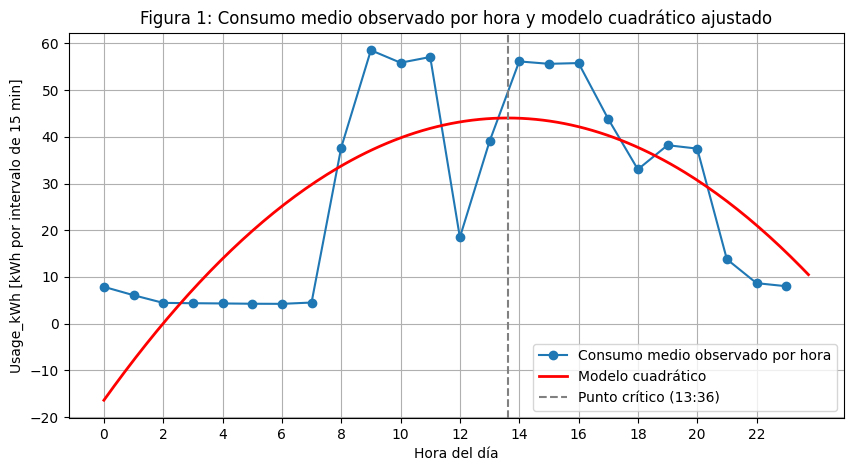

In [118]:
# A.1 DERIVACIÓN
# Modelo cuadrático: ŷ = β0 + β1·x + β2·x², con x = NSM (segundos desde la medianoche)


# 1. Datos
x = df['NSM'].values            # Segundos desde la medianoche
y = df['Usage_kWh'].values      # Consumo en kWh


# 2. Ajuste por mínimos cuadrados (polyfit devuelve los coeficientes de mayor a menor grado)
beta_2, beta_1, beta_0 = np.polyfit(x, y, 2)     # modelo Cuadrático: ŷ = beta_0 + beta_1*x + beta_2*x^2
beta_1_lin, beta_0_lin = np.polyfit(x, y, 1)    #  modelo Lineal: ŷ = beta_0_lin + beta_1_lin*x

def y_cuad(t):
    """Consumo esperado según el modelo cuadrático en el instante t (segundos)."""
    return beta_0 + beta_1 * t + beta_2 * t**2

def derivada(t):
    """dŷ/dx = β1 + 2·β2·x  (kWh por segundo)."""
    return beta_1 + 2 * beta_2 * t

print("=== RESULTADOS MODELO CUADRÁTICO ===")
print(f"beta_0 = {beta_0:.6f}")
print(f"beta_1 = {beta_1:.8e}")
print(f"beta_2 = {beta_2:.8e}\n")

print("=== RESULTADOS MODELO LINEAL ===")
print(f"beta_0_lin = {beta_0_lin:.6f}")
print(f"beta_1_lin = {beta_1_lin:.8e} kWh/s ({beta_1_lin*3600:.4f} kWh/h)  (derivada constante)\n")

print(f"Rango observado de NSM: [{x.min()} ; {x.max()}] s\n")

# 3. Derivada evaluada en los extremos del rango
# Como dŷ/dx es lineal en x, sus valores máximo y mínimo dentro del rango
# se alcanzan en los extremos: estos dos puntos muestran todo su recorrido
x1 = x.min()   # 0 s     = 00:00
x2 = x.max()   # 85500 s = 23:45

print("=== EVALUACIÓN DE LA DERIVADA ===")
for t, hora in [(x1, "00:00"), (x2, "23:45")]:
    print(f"dy/dx en x = {t} s ({hora} hs): {derivada(t):.8e} kWh/s "
          f"({derivada(t)*3600:.4f} kWh/h)   ŷ = {y_cuad(t):.2f} kWh")
print()

# 4. Punto crítico y clasificación
x_crit = -beta_1 / (2 * beta_2)     # dŷ/dx = 0
hora_crit = x_crit / 3600
d2y_dx2 = 2 * beta_2                # derivada segunda (constante)

print("=== PUNTO CRÍTICO ===")
print(f"x_crítico = {x_crit:.2f} segundos")
print(f"Hora = {hora_crit:.2f} h ≈ {int(hora_crit):02d}:{int((hora_crit % 1) * 60):02d}")
print(f"Derivada segunda = {d2y_dx2:.8e}  ->  {'máximo' if d2y_dx2 < 0 else 'mínimo'}")
print(f"x_crítico dentro del rango observado: {x.min() <= x_crit <= x.max()}")
print(f"ŷ(x_crítico) = {y_cuad(x_crit):.2f} kWh\n")

# 6. Comparación con el consumo medio observado
media_por_instante = pd.Series(y).groupby(x).mean()   # promedio de cada horario de 15 min
print("=== MODELO vs. CONSUMO MEDIO OBSERVADO ===")
for t, hora in [(0, "00:00"), (7200, "02:00"), (21600, "06:00"), (28800, "08:00"),
                (30600, "08:30"), (81000, "22:30"), (85500, "23:45")]:
    print(f"{hora}:  observado = {media_por_instante[t]:6.2f} kWh   modelo = {y_cuad(t):6.2f} kWh")

# 7. Figura 1: perfil horario observado vs. modelo cuadrático
perfil = pd.Series(y).groupby(x // 3600).mean()       # consumo medio por hora
horas = np.linspace(x.min(), x.max(), 200)
plt.figure(figsize=(10, 5))
plt.plot(perfil.index, perfil.values, 'o-', label='Consumo medio observado por hora')
plt.plot(horas / 3600, y_cuad(horas), 'r-', linewidth=2, label='Modelo cuadrático')
plt.axvline(hora_crit, color='gray', linestyle='--', label=f'Punto crítico ({int(hora_crit):02d}:{int((hora_crit % 1) * 60):02d})')
plt.xticks(range(0, 24, 2))
plt.xlabel('Hora del día')
plt.ylabel('Usage_kWh [kWh por intervalo de 15 min]')
plt.title('Figura 1: Consumo medio observado por hora y modelo cuadrático ajustado')
plt.legend()
plt.grid(True)
plt.show()


###A.2 Derivadas parciales y ecuaciones normales

In [119]:
# A.2 DERIVADAS PARCIALES Y ECUACIONES NORMALES
# Recta de mínimos cuadrados de Usage_kWh sobre Lagging_Current_Reactive.Power_kVarh

# 1. Datos
x = df['Lagging_Current_Reactive.Power_kVarh'].values
y = df['Usage_kWh'].values
n = len(df)

# 2. Vía 1: fórmulas obtenidas a mano
x_bar = np.mean(x)
y_bar = np.mean(y)

sum_x2 = np.sum(x**2)
sum_xy = np.sum(x * y)

Sxx = sum_x2 - n * (x_bar**2)
Sxy = sum_xy - n * x_bar * y_bar

beta_1_formula = Sxy / Sxx
beta_0_formula = y_bar - beta_1_formula * x_bar

# 3. Vía 2: función de regresión de NumPy
beta_1_python, beta_0_python = np.polyfit(x, y, 1)

# 4. Resultados y contraste
print("=== VÍA 1: FÓRMULAS ANALÍTICAS (MÍNIMOS CUADRADOS) ===")
print(f"x̄ = {x_bar:.4f} kVarh,  ȳ = {y_bar:.4f} kWh")
print(f"Sxx = {Sxx:.8f}")
print(f"Sxy = {Sxy:.8f}")
print(f"beta_1 = {beta_1_formula:.10f}")
print(f"beta_0 = {beta_0_formula:.10f}\n")

print("=== VÍA 2: HERRAMIENTA AUTOMÁTICA (np.polyfit) ===")
print(f"beta_1 = {beta_1_python:.10f}")
print(f"beta_0 = {beta_0_python:.10f}\n")

print("=== CONTRASTE Y VERIFICACIÓN ===")
print(f"Diferencia absoluta en beta_1: {abs(beta_1_formula - beta_1_python):.2e}")
print(f"Diferencia absoluta en beta_0: {abs(beta_0_formula - beta_0_python):.2e}\n")

# 5. Sistema de ecuaciones normales con los datos
sum_x, sum_y = np.sum(x), np.sum(y)
print("=== SISTEMA DE ECUACIONES NORMALES ===")
print(f"n = {n}, Σx = {sum_x:.4f}, Σy = {sum_y:.4f}, Σx² = {sum_x2:.4f}, Σxy = {sum_xy:.4f}")
print(f"{n}·b0 + {sum_x:.4f}·b1 = {sum_y:.4f}")
print(f"{sum_x:.4f}·b0 + {sum_x2:.4f}·b1 = {sum_xy:.4f}")
A = np.array([[n, sum_x], [sum_x, sum_x2]])
c = np.array([sum_y, sum_xy])
print("Solución del sistema (b0, b1):", np.linalg.solve(A, c))

# 6. Recta obtenida y rango observado de x
print(f"\nRecta obtenida: ŷ = {beta_0_formula:.4f} + {beta_1_formula:.4f}·x")
print(f"Rango observado de x: [{x.min()} ; {x.max()}] kVarh")

=== VÍA 1: FÓRMULAS ANALÍTICAS (MÍNIMOS CUADRADOS) ===
x̄ = 13.0354 kVarh,  ȳ = 27.3869 kWh
Sxx = 9316366.76904493
Sxy = 17123910.41031603
beta_1 = 1.8380459717
beta_0 = 3.4272581642

=== VÍA 2: HERRAMIENTA AUTOMÁTICA (np.polyfit) ===
beta_1 = 1.8380459717
beta_0 = 3.4272581642

=== CONTRASTE Y VERIFICACIÓN ===
Diferencia absoluta en beta_1: 2.22e-16
Diferencia absoluta en beta_0: 4.44e-16

=== SISTEMA DE ECUACIONES NORMALES ===
n = 35040, Σx = 456759.8400, Σy = 959636.7100, Σx² = 15270406.4790, Σxy = 29633143.0050
35040·b0 + 456759.8400·b1 = 959636.7100
456759.8400·b0 + 15270406.4790·b1 = 29633143.0050
Solución del sistema (b0, b1): [3.42725816 1.83804597]

Recta obtenida: ŷ = 3.4273 + 1.8380·x
Rango observado de x: [0.0 ; 96.91] kVarh


###A.3 Descenso del gradiente

α = 1e-7 (demasiado pequeña)   iteraciones = 10000   f final = 3.9511e+06   (se alcanzó el máximo de iteraciones)
α = 5e-6 (adecuada)            iteraciones =   255   f final = 3.9511e+06   (‖∇f‖ < 1e-06)
α = 1.5e-5 (diverge)           iteraciones =   197   f final = 1.0472e+20   (divergencia (f > 10^20))


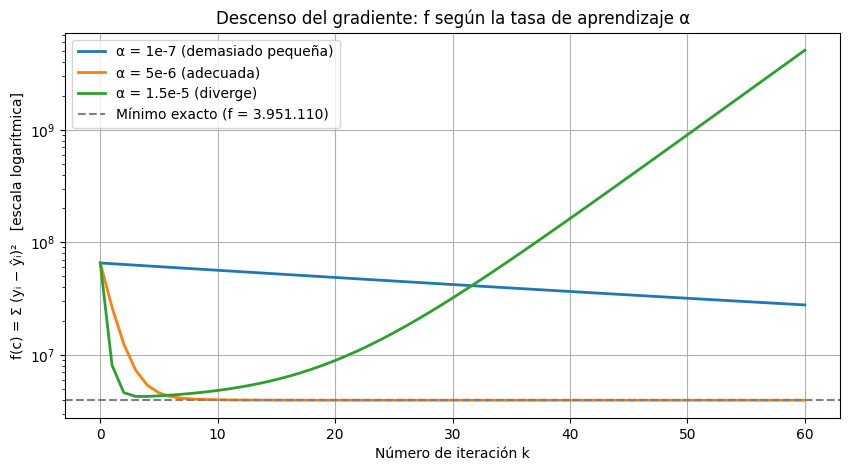


                                          Descenso del gradiente  Mínimos cuadrados exacto  Diferencia absoluta
b0 (intercepto)                                 -4.50565108e+01           -4.50565108e+01       9.21573928e-11
b1 Lagging_Current_Reactive.Power_kVarh          1.51373585e+00            1.51373585e+00       1.49080748e-12
b2 Leading_Current_Reactive_Power_kVarh         -1.10168123e+00           -1.10168123e+00       4.55546711e-12
b3 Lagging_Current_Power_Factor                  6.71764105e-01            6.71764105e-01       1.71573866e-12
b4 NSM                                           6.65820229e-05            6.65820229e-05       2.09549175e-16

f final (descenso del gradiente) = 3951110.3411
f mínimo (solución exacta)      = 3951110.3411


In [120]:
# A.3 DESCENSO DEL GRADIENTE
# Modelo de B.5: Usage_kWh = b0 + b1·x1 + b2·x2 + b3·x3 + b4·x4
# Se itera sobre los coeficientes c de las predictoras estandarizadas:
# c(k+1) = c(k) − α · ∇f(c(k))

# 1. Datos
predictoras = [
    'Lagging_Current_Reactive.Power_kVarh',   # x1
    'Leading_Current_Reactive_Power_kVarh',   # x2
    'Lagging_Current_Power_Factor',           # x3
    'NSM'                                     # x4
]
X_datos = df[predictoras].values              # 35040 filas x 4 columnas
y = df['Usage_kWh'].values                    # 35040 valores
n = len(y)

# 2. Estandarización de las predictoras
# Las variables tienen escalas muy distintas (NSM llega a 85500, los kVarh a ~100).
# Se lleva cada una a media 0 y desvío 1 para que un mismo α sirva para todos los coeficientes.
media = np.mean(X_datos, axis=0)              # media de cada columna
desvio = np.std(X_datos, axis=0)              # desvío de cada columna
Z = (X_datos - media) / desvio

# Matriz de diseño: columna de unos (para c0) + las 4 predictoras estandarizadas
X = np.column_stack([np.ones(n), Z])          # 35040 x 5

# 3. Función a minimizar y su gradiente
def f(c):
    """f(c) = Σ (yi − ŷi)²  (suma de cuadrados de los residuos, como en A.2)"""
    residuos = y - X @ c
    return np.sum(residuos ** 2)

def grad_f(c):
    """∇f(c) = −2 · Xᵀ (y − X c)  (vector con las 5 derivadas parciales ∂f/∂cj)"""
    residuos = y - X @ c
    return -2 * X.T @ residuos

# 4. Descenso del gradiente
def descenso_gradiente(alpha, max_iter=10000, tol=1e-6):
    c = np.zeros(5)                           # punto inicial c(0) = (0, 0, 0, 0, 0)
    historial_f = [f(c)]                      # valores de f en cada iteración
    criterio = "se alcanzó el máximo de iteraciones"
    for k in range(max_iter):
        gradiente = grad_f(c)
        if np.linalg.norm(gradiente) < tol:   # criterio de detención: ‖∇f‖ < tol
            criterio = f"‖∇f‖ < {tol}"
            break
        c = c - alpha * gradiente             # regla de actualización
        historial_f.append(f(c))
        if historial_f[-1] > 1e20:            # corte de seguridad si diverge
            criterio = "divergencia (f > 10^20)"
            break
    return c, historial_f, len(historial_f) - 1, criterio

# 5. Tres tasas de aprendizaje
tasas = {
    'α = 1e-7 (demasiado pequeña)': 1e-7,
    'α = 5e-6 (adecuada)':          5e-6,
    'α = 1.5e-5 (diverge)':         1.5e-5,
}
resultados = {}
for nombre, alpha in tasas.items():
    c, historial_f, iteraciones, criterio = descenso_gradiente(alpha)
    resultados[nombre] = (c, historial_f)
    print(f"{nombre:<30} iteraciones = {iteraciones:>5}   f final = {historial_f[-1]:.4e}   ({criterio})")

# 6. Solución exacta de mínimos cuadrados (B.5)
X_original = np.column_stack([np.ones(n), X_datos])
b_exacta = np.linalg.solve(X_original.T @ X_original, X_original.T @ y)   # (XᵀX)⁻¹ XᵀY
f_minimo = np.sum((y - X_original @ b_exacta) ** 2)

# 7. Gráfico (Figura 2): f en función del número de iteración
plt.figure(figsize=(10, 5))
for nombre, (c, historial_f) in resultados.items():
    plt.plot(historial_f[:61], label=nombre, linewidth=2)
plt.axhline(f_minimo, color='gray', linestyle='--',
            label=f'Mínimo exacto (f = {f_minimo:,.0f})'.replace(',', '.'))
plt.yscale('log')
plt.xlabel('Número de iteración k')
plt.ylabel('f(c) = Σ (yᵢ − ŷᵢ)²   [escala logarítmica]')
plt.title('Descenso del gradiente: f según la tasa de aprendizaje α')
plt.legend()
plt.grid(True)
plt.show()

# 8. Comparación con la solución exacta
# Se pasan los coeficientes c a las unidades originales: bj = cj/sj, b0 = c0 − Σ cj·x̄j/sj
c_adecuada = resultados['α = 5e-6 (adecuada)'][0]
b_gradiente = np.zeros(5)
b_gradiente[1:] = c_adecuada[1:] / desvio
b_gradiente[0] = c_adecuada[0] - np.sum(c_adecuada[1:] * media / desvio)

comparacion = pd.DataFrame({
    'Descenso del gradiente': b_gradiente,
    'Mínimos cuadrados exacto': b_exacta,
    'Diferencia absoluta': np.abs(b_gradiente - b_exacta)
}, index=['b0 (intercepto)'] + [f'b{j+1} {p}' for j, p in enumerate(predictoras)])
print("\n", comparacion.to_string(float_format=lambda v: f"{v:.8e}"))

f_final = resultados['α = 5e-6 (adecuada)'][1][-1]
print(f"\nf final (descenso del gradiente) = {f_final:.4f}")
print(f"f mínimo (solución exacta)      = {f_minimo:.4f}")

### B.1 Varianza

In [121]:
# B.1 VARIANZA
# Modelo simple de A.2: Usage_kWh = β0 + β1 · Lagging_Current_Reactive.Power_kVarh
# Se reutilizan x, y, n, y_bar, beta_0_formula y beta_1_formula de A.2

# 1. Valores ajustados por la recta de A.2
y_hat = beta_0_formula + beta_1_formula * x

# 2. Sumas de cuadrados, calculadas por definición
STC = np.sum((y - y_bar) ** 2)                # total
SCR = np.sum((y_hat - y_bar) ** 2)            # explicada por la regresión
SCE = np.sum((y - y_hat) ** 2)                # no explicada (residuos)
Syy = STC                                     # en el apunte, Syy = Σ(yi − ȳ)² = STC (se usa en B.2 para r)

# 3. Tabla de descomposición de la variabilidad (Tabla 2 del informe)
tabla_varianza = pd.DataFrame({
    'Suma de cuadrados': [SCR, SCE, STC],
    'Proporción de STC': [SCR / STC, SCE / STC, STC / STC]
}, index=['SCR (explicada por la regresión)',
          'SCE (no explicada)',
          'STC (total)'])
print(tabla_varianza.to_string(float_format=lambda v: f"{v:,.4f}"))

# 4. Verificación: STC = SCR + SCE
print(f"\nSCR + SCE = {SCR + SCE:,.4f}")
print(f"STC       = {STC:,.4f}")
print(f"Diferencia (SCR + SCE − STC) = {SCR + SCE - STC:.3e}")

# 5. Estimación de la varianza del modelo
sigma2 = SCE / (n - 2)
print(f"\nσ̂² = SCE / (n − 2) = {SCE:,.4f} / {n - 2} = {sigma2:.4f} kWh²")
print(f"σ̂  = {np.sqrt(sigma2):.4f} kWh")

# 6. Coeficiente de determinación
R2 = 1 - SCE / STC
print(f"\nR² = 1 − SCE / STC = {R2:.6f}")

                                  Suma de cuadrados  Proporción de STC
SCR (explicada por la regresión)    31,474,534.5487             0.8031
SCE (no explicada)                   7,717,516.6780             0.1969
STC (total)                         39,192,051.2267             1.0000

SCR + SCE = 39,192,051.2267
STC       = 39,192,051.2267
Diferencia (SCR + SCE − STC) = 0.000e+00

σ̂² = SCE / (n − 2) = 7,717,516.6780 / 35038 = 220.2613 kWh²
σ̂  = 14.8412 kWh

R² = 1 − SCE / STC = 0.803085


### B.2 Regresión lineal simple


t(0,025; 35038) = 1.9600

                                                ŷ = β̂1·x + β̂0      σ̂²      R²       r                  IC(β1)           IC(β0)          ICM(Y|x*)          IP(Y|x*)
Lagging_Current_Reactive.Power_kVarh      1.838046·x + 3.427258   220.26  0.8031  0.8961         [1.829 ; 1.848]  [3.228 ; 3.626]    [40.02 ; 40.36]    [11.1 ; 69.28]
Leading_Current_Reactive_Power_kVarh      -1.463649·x + 33.0526  1000.47  0.1056 -0.3249       [-1.508 ; -1.419]  [32.68 ; 33.43]    [2.988 ; 4.572]  [-58.22 ; 65.78]
Lagging_Current_Power_Factor            0.6822043·x + -27.58381   951.93  0.1490  0.3860       [0.6651 ; 0.6993]   [-29 ; -26.17]  [-15.02 ; -12.86]  [-74.42 ; 46.54]
NSM                                   0.0003146042·x + 13.93756  1056.99  0.0550  0.2346  [0.000301 ; 0.0003283]  [13.26 ; 14.61]    [13.27 ; 14.62]  [-49.78 ; 77.67]

Intervalos con factor de potencia ≤ 25 %: 1 de 35040

Mayor R²: Lagging_Current_Reactive.Power_kVarh (R² = 0.8031)


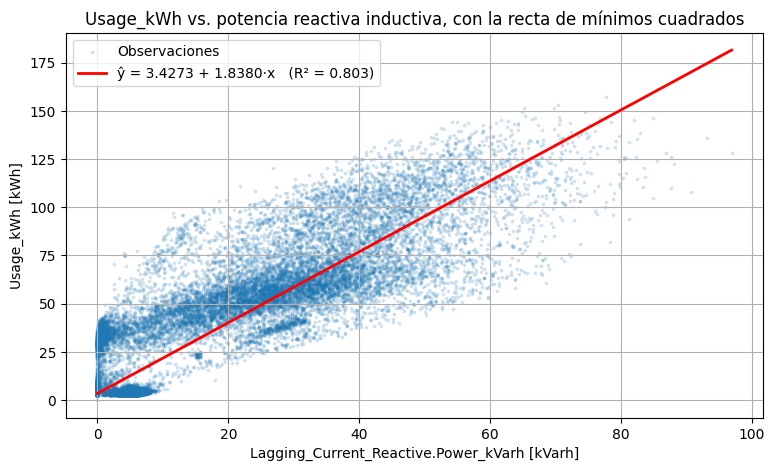

In [122]:
# B.2 REGRESIÓN LINEAL SIMPLE
# Usage_kWh sobre cada una de las 4 variables, intervalos al 95 %, x* = 20 (valor de B.4)
# Para Lagging_Current_Reactive.Power_kVarh se reutiliza lo calculado en A.2 y B.1


# 1. Valores comunes
x_star = 20                                   # valor fijo de B.4
t_crit = stats.t.ppf(1 - 0.05 / 2, n - 2)     # t(α/2, n−2) con α = 0,05
print(f"t(0,025; {n - 2}) = {t_crit:.4f}\n")

# 2. Ajuste de la recta para una variable nueva
# Mismas fórmulas que en A.2 y B.1: Sxy/Sxx, ȳ − β̂1·x̄, SCE/(n−2), 1 − SCE/STC
def ajuste_simple(xv):
    xv_bar = np.mean(xv)
    Sxx_v = np.sum(xv ** 2) - n * xv_bar ** 2
    Sxy_v = np.sum(xv * y) - n * xv_bar * y_bar
    b1 = Sxy_v / Sxx_v
    b0 = y_bar - b1 * xv_bar
    SCE_v = np.sum((y - (b0 + b1 * xv)) ** 2)  # SCE = Σ(yi − ŷi)², como en B.1
    return {'b0': b0, 'b1': b1, 'x_bar': xv_bar, 'Sxx': Sxx_v,
            'sigma2': SCE_v / (n - 2),
            'R2': 1 - SCE_v / STC,              # STC no depende de x: es la de B.1
            'r': Sxy_v / np.sqrt(Sxx_v * Syy)}

# 3. Intervalos de confianza y de predicción (fórmulas del apunte)
def intervalos(m):
    e_b1 = t_crit * np.sqrt(m['sigma2'] / m['Sxx'])
    e_b0 = t_crit * np.sqrt(m['sigma2'] * (1 / n + m['x_bar'] ** 2 / m['Sxx']))
    y_star = m['b0'] + m['b1'] * x_star
    termino = 1 / n + (x_star - m['x_bar']) ** 2 / m['Sxx']
    e_icm = t_crit * np.sqrt(m['sigma2'] * termino)
    e_ip = t_crit * np.sqrt(m['sigma2'] * (1 + termino))
    m['IC_b1'] = (m['b1'] - e_b1, m['b1'] + e_b1)
    m['IC_b0'] = (m['b0'] - e_b0, m['b0'] + e_b0)
    m['y_star'] = y_star
    m['ICM'] = (y_star - e_icm, y_star + e_icm)
    m['IP'] = (y_star - e_ip, y_star + e_ip)
    return m

# 4. Las cuatro regresiones
variables = ['Lagging_Current_Reactive.Power_kVarh',
             'Leading_Current_Reactive_Power_kVarh',
             'Lagging_Current_Power_Factor',
             'NSM']

modelos = {}
# Lagging kVarh: todo ya está calculado en A.2 (recta) y B.1 (σ̂², R²)
modelos[variables[0]] = {'b0': beta_0_formula, 'b1': beta_1_formula, 'x_bar': x_bar,
                         'Sxx': Sxx, 'sigma2': sigma2, 'R2': R2,
                         'r': Sxy / np.sqrt(Sxx * Syy)}
# Las otras tres se ajustan ahora
for v in variables[1:]:
    modelos[v] = ajuste_simple(df[v].values)

for v in variables:
    intervalos(modelos[v])

# 5. Cuadro del enunciado
fmt = lambda iv: f"[{iv[0]:.4g} ; {iv[1]:.4g}]"
cuadro = pd.DataFrame({
    'ŷ = β̂1·x + β̂0': [f"{m['b1']:.7g}·x + {m['b0']:.7g}" for m in modelos.values()],
    'σ̂²':            [round(m['sigma2'], 2) for m in modelos.values()],
    'R²':             [round(m['R2'], 4) for m in modelos.values()],
    'r':              [round(m['r'], 4) for m in modelos.values()],
    'IC(β1)':         [fmt(m['IC_b1']) for m in modelos.values()],
    'IC(β0)':         [fmt(m['IC_b0']) for m in modelos.values()],
    'ICM(Y|x*)':      [fmt(m['ICM']) for m in modelos.values()],
    'IP(Y|x*)':       [fmt(m['IP']) for m in modelos.values()],
}, index=variables)
pd.set_option('display.width', 250)
print(cuadro.to_string())
fp = df['Lagging_Current_Power_Factor'].values
print(f"\nIntervalos con factor de potencia ≤ 25 %: {(fp <= 25).sum()} de {n}")

# 6. Variable que mejor responde a Usage_kWh
mejor = max(modelos, key=lambda v: modelos[v]['R2'])
print(f"\nMayor R²: {mejor} (R² = {modelos[mejor]['R2']:.4f})")

#7. Diagrama de dispersión con la recta ajustada
m = modelos[mejor]
xv = df[mejor].values
x_linea = np.linspace(xv.min(), xv.max(), 100)

plt.figure(figsize=(9, 5))
plt.scatter(xv, y, s=3, alpha=0.15, label='Observaciones')
plt.plot(x_linea, m['b0'] + m['b1'] * x_linea, color='red', linewidth=2,
         label=f"ŷ = {m['b0']:.4f} + {m['b1']:.4f}·x   (R² = {m['R2']:.3f})")
plt.xlabel(f'{mejor} [kVarh]')
plt.ylabel('Usage_kWh [kWh]')
plt.title('Usage_kWh vs. potencia reactiva inductiva, con la recta de mínimos cuadrados')
plt.legend()
plt.grid(True)
plt.show()

### B.3 Test de Hipótesis

In [123]:
# B.3 TEST DE HIPÓTESIS SOBRE LA PENDIENTE
# Modelo elegido en B.2: Usage_kWh sobre Lagging_Current_Reactive.Power_kVarh
# H0: β1 = 0    contra    H1: β1 ≠ 0      nivel α = 0,05
# Se reutilizan beta_1_formula y Sxx (A.2), sigma2 (B.1), t_crit y n (B.2)

# 1. Estadístico de prueba: T = β̂1 / √(σ̂² / Sxx)
# Bajo H0 tiene distribución t de Student con n − 2 grados de libertad
error_estandar_b1 = np.sqrt(sigma2 / Sxx)
T = beta_1_formula / error_estandar_b1

# 2. Regla de decisión: rechazar H0 si |T| > t(α/2, n−2)
rechazo_H0 = abs(T) > t_crit

# 3. Resultados
print(f"β̂1 = {beta_1_formula:.6f}")
print(f"√(σ̂² / Sxx) = √({sigma2:.4f} / {Sxx:.4f}) = {error_estandar_b1:.7f}")
print(f"T = β̂1 / √(σ̂² / Sxx) = {T:.4f}")
print(f"Valor crítico t(0,025; {n - 2}) = {t_crit:.4f}")
print(f"|T| > t crítico: {rechazo_H0}  ->  {'se rechaza H0' if rechazo_H0 else 'no se rechaza H0'}")

β̂1 = 1.838046
√(σ̂² / Sxx) = √(220.2613 / 9316366.7690) = 0.0048623
T = β̂1 / √(σ̂² / Sxx) = 378.0163
Valor crítico t(0,025; 35038) = 1.9600
|T| > t crítico: True  ->  se rechaza H0


### B.4 Intervalos para la respuesta media y de predicción


In [124]:
# B.4 INTERVALOS PARA LA RESPUESTA MEDIA Y DE PREDICCIÓN
# Modelo simple sobre Lagging_Current_Reactive.Power_kVarh, x* = 20 kVarh
# Los intervalos ya se calcularon en B.2 (función intervalos): se toman de ahí
#   ICM: ŷ* ± t·√(σ̂²·(1/n + (x* − x̄)²/Sxx))      IP: ŷ* ± t·√(σ̂²·(1 + 1/n + (x* − x̄)²/Sxx))

# 1. Resultados guardados en B.2 para la variable elegida
m_x1 = modelos['Lagging_Current_Reactive.Power_kVarh']
y_star = m_x1['y_star']
ICM = m_x1['ICM']
IP = m_x1['IP']

# 2. Semiancho de cada intervalo
semiancho_ICM = (ICM[1] - ICM[0]) / 2
semiancho_IP = (IP[1] - IP[0]) / 2

# 3. Resultados
print(f"ŷ* = {beta_0_formula:.4f} + {beta_1_formula:.4f} · {x_star} = {y_star:.4f} kWh\n")
print(f"ICM 95%: {y_star:.4f} ± {semiancho_ICM:.4f} = [{ICM[0]:.4f} ; {ICM[1]:.4f}]")
print(f"IP  95%: {y_star:.4f} ± {semiancho_IP:.4f} = [{IP[0]:.4f} ; {IP[1]:.4f}]")
print(f"El IP es {semiancho_IP / semiancho_ICM:.0f} veces más ancho que el ICM")

ŷ* = 3.4273 + 1.8380 · 20 = 40.1882 kWh

ICM 95%: 40.1882 ± 0.1690 = [40.0192 ; 40.3572]
IP  95%: 40.1882 ± 29.0897 = [11.0985 ; 69.2779]
El IP es 172 veces más ancho que el ICM


### B.5 Regresión múltiple


In [125]:
# B.5 REGRESIÓN MÚLTIPLE
# Usage_kWh = β0 + β1·x1 + β2·x2 + β3·x3 + β4·x4
# Se reutilizan X_original y predictoras (A.3), STC y R2 (B.1)

# 1. Ecuaciones normales en forma matricial: β̂ = (XᵀX)⁻¹ XᵀY
# X_original (A.3): columna de unos + las 4 predictoras en sus unidades originales
XtX = X_original.T @ X_original
XtY = X_original.T @ y
beta_hat = np.linalg.inv(XtX) @ XtY

nombres = ['β0 (intercepto)'] + [f'β{j+1} {p}' for j, p in enumerate(predictoras)]
print(pd.Series(beta_hat, index=nombres).to_string(float_format=lambda v: f"{v:.6e}"))
print(f"\nβ4 por hora = β4 · 3600 = {beta_hat[4] * 3600:.4f} kWh")   # NSM está en segundos

# 2. SCE y R² del modelo múltiple
k = len(predictoras)                          # 4 predictoras
SCE_m = np.sum((y - X_original @ beta_hat) ** 2)
R2_m = 1 - SCE_m / STC                        # STC no cambia: es la misma de B.1
print(f"\nSCE = {SCE_m:.4f}")
print(f"R² = 1 − SCE / STC = {R2_m:.6f}")

# 3. R² ajustado con la fórmula del enunciado: 1 − (1 − R²)·(n − k)/(n − k − 1)
R2a_m = 1 - (1 - R2_m) * (n - k) / (n - k - 1)
R2a_s = 1 - (1 - R2) * (n - 1) / (n - 1 - 1)  # modelo simple de B.2 (k = 1)

# 4. Comparación simple vs. múltiple (Tabla 6 del informe)
comparacion_modelos = pd.DataFrame({
    'k': [1, k],
    'R²': [R2, R2_m],
    'R² ajustado': [R2a_s, R2a_m],
}, index=['Simple (Lagging kVarh)', 'Múltiple (4 variables)'])
print("\n", comparacion_modelos.to_string(float_format=lambda v: f"{v:.6f}"))

β0 (intercepto)                           -4.505651e+01
β1 Lagging_Current_Reactive.Power_kVarh    1.513736e+00
β2 Leading_Current_Reactive_Power_kVarh   -1.101681e+00
β3 Lagging_Current_Power_Factor            6.717641e-01
β4 NSM                                     6.658202e-05

β4 por hora = β4 · 3600 = 0.2397 kWh

SCE = 3951110.3411
R² = 1 − SCE / STC = 0.899186

                         k       R²  R² ajustado
Simple (Lagging kVarh)  1 0.803085     0.803079
Múltiple (4 variables)  4 0.899186     0.899183
